In [124]:
#import laibararies
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings('ignore')

In [125]:
#load the data
df_train = pd.read_csv(r"C:\Users\AHSAN GHANI\Documents\6Month Intership program\Frist Month\pandas_tip&trick\Deep Learning\Project\Dataset\bank churn dataset\train.csv")
df_test = pd.read_csv(r"C:\Users\AHSAN GHANI\Documents\6Month Intership program\Frist Month\pandas_tip&trick\Deep Learning\Project\Dataset\bank churn dataset\test.csv")
df_submission = pd.read_csv(r"C:\Users\AHSAN GHANI\Documents\6Month Intership program\Frist Month\pandas_tip&trick\Deep Learning\Project\Dataset\bank churn dataset\sample_submission.csv")

In [126]:
df_train.head()

,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15674932,Okwudilichukwu,668,France,Male,33.0,3,0.00,2,1.0,0.0,181449.97,0
1,1,15749177,Okwudiliolisa,627,France,Male,33.0,1,0.00,2,1.0,1.0,49503.50,0
2,2,15694510,Hsueh,678,France,Male,40.0,10,0.00,2,1.0,0.0,184866.69,0
3,3,15741417,Kao,581,France,Male,34.0,2,148882.54,1,1.0,1.0,84560.88,0
4,4,15766172,Chiemenam,716,Spain,Male,33.0,5,0.00,2,1.0,1.0,15068.83,0


In [127]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 165034 entries, 0 to 165033
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   id               165034 non-null  int64  
 1   CustomerId       165034 non-null  int64  
 2   Surname          165034 non-null  str    
 3   CreditScore      165034 non-null  int64  
 4   Geography        165034 non-null  str    
 5   Gender           165034 non-null  str    
 6   Age              165034 non-null  float64
 7   Tenure           165034 non-null  int64  
 8   Balance          165034 non-null  float64
 9   NumOfProducts    165034 non-null  int64  
 10  HasCrCard        165034 non-null  float64
 11  IsActiveMember   165034 non-null  float64
 12  EstimatedSalary  165034 non-null  float64
 13  Exited           165034 non-null  int64  
dtypes: float64(5), int64(6), str(3)
memory usage: 17.6 MB


In [128]:
df = df_train.copy()

In [129]:
#check the null values
df.isnull().sum()

id                 0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [130]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,165034.0,8.251650e+04,47641.356500,0.00,41258.25,82516.5,1.237748e+05,165033.00
CustomerId,165034.0,1.569201e+07,71397.816791,15565701.00,15633141.00,15690169.0,1.575682e+07,15815690.00
CreditScore,165034.0,6.564544e+02,80.103340,350.00,597.00,659.0,7.100000e+02,850.00
Age,165034.0,3.812589e+01,8.867205,18.00,32.00,37.0,4.200000e+01,92.00
Tenure,165034.0,5.020353e+00,2.806159,0.00,3.00,5.0,7.000000e+00,10.00
Balance,165034.0,5.547809e+04,62817.663278,0.00,0.00,0.0,1.199395e+05,250898.09
NumOfProducts,165034.0,1.554455e+00,0.547154,1.00,1.00,2.0,2.000000e+00,4.00
HasCrCard,165034.0,7.539537e-01,0.430707,0.00,1.00,1.0,1.000000e+00,1.00
IsActiveMember,165034.0,4.977702e-01,0.499997,0.00,0.00,0.0,1.000000e+00,1.00
EstimatedSalary,165034.0,1.125748e+05,50292.865585,11.58,74637.57,117948.0,1.551525e+05,199992.48


In [131]:
df.columns

Index(['id', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender',
       'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='str')

In [132]:
cat_col = ['IsActiveMember','Tenure', 'NumOfProducts', 'HasCrCard','Exited','Geography', 'Gender']
num_col = ['CreditScore','Age','Balance','EstimatedSalary']

#find the values count of catagorical columns
for col in cat_col:
    print(df[col].value_counts())
    print()

IsActiveMember
0.0    82885
1.0    82149
Name: count, dtype: int64

Tenure
2     18045
7     17810
4     17554
8     17520
5     17268
1     16760
9     16709
3     16630
6     15822
10     5909
0      5007
Name: count, dtype: int64

NumOfProducts
2    84291
1    77374
3     2894
4      475
Name: count, dtype: int64

HasCrCard
1.0    124428
0.0     40606
Name: count, dtype: int64

Exited
0    130113
1     34921
Name: count, dtype: int64

Geography
France     94215
Spain      36213
Germany    34606
Name: count, dtype: int64

Gender
Male      93150
Female    71884
Name: count, dtype: int64



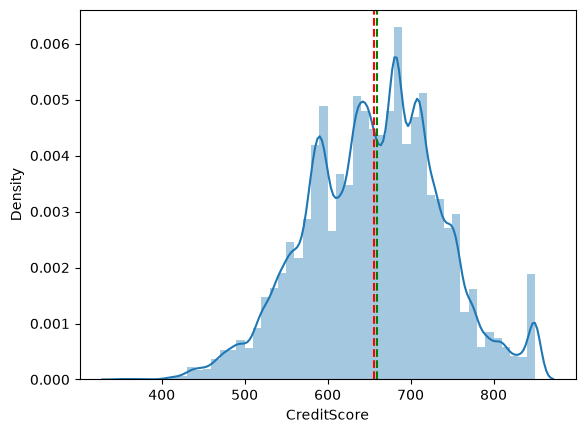

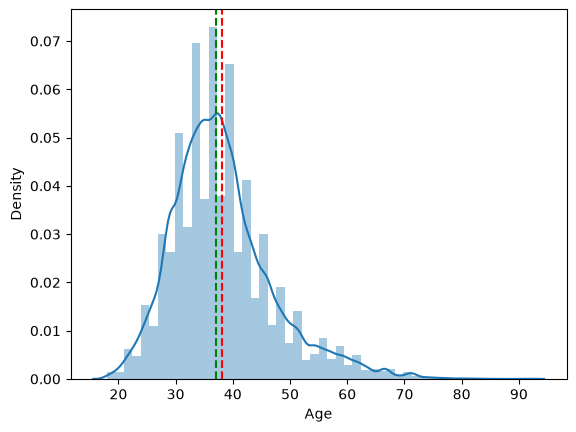

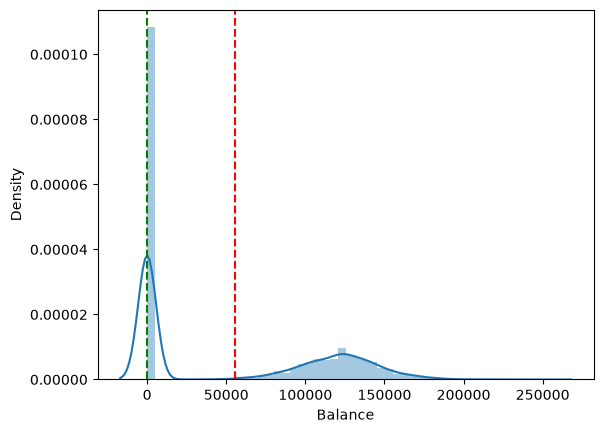

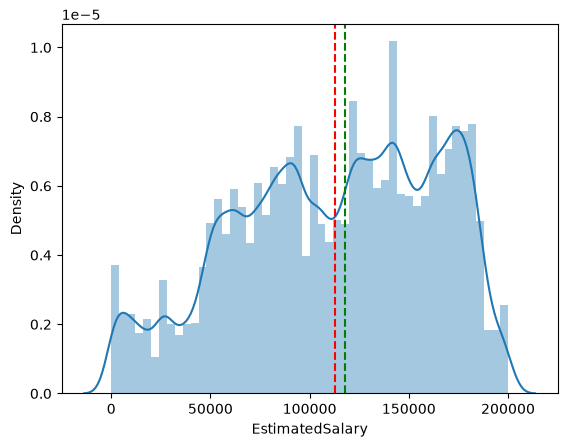

In [133]:
#create histogram of num_col
for col in num_col:
    sns.distplot(df[col],kde=True)
    plt.axvline(df[col].mean(),color='r',linestyle='--',label='Mean')
    plt.axvline(df[col].median(),color='g',linestyle='--',label='Median')


    plt.show()

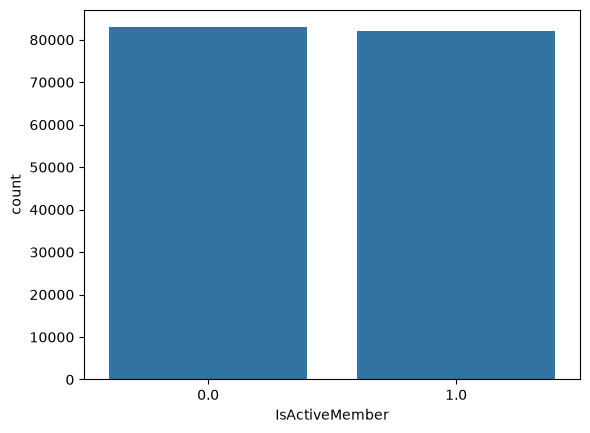

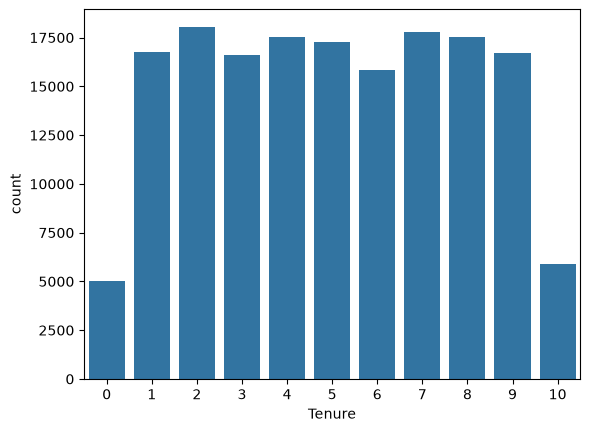

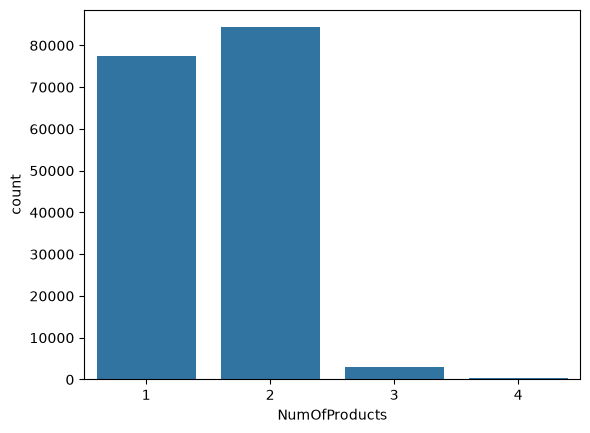

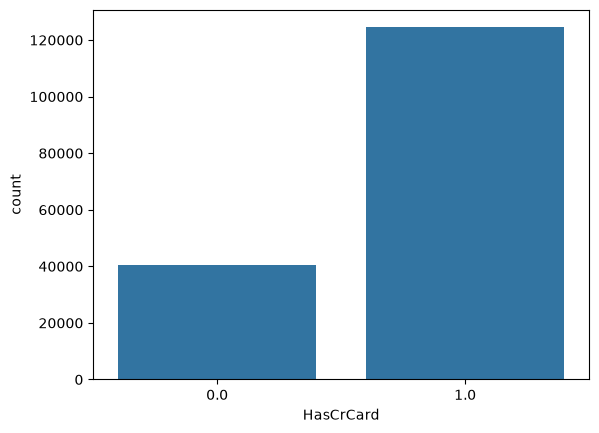

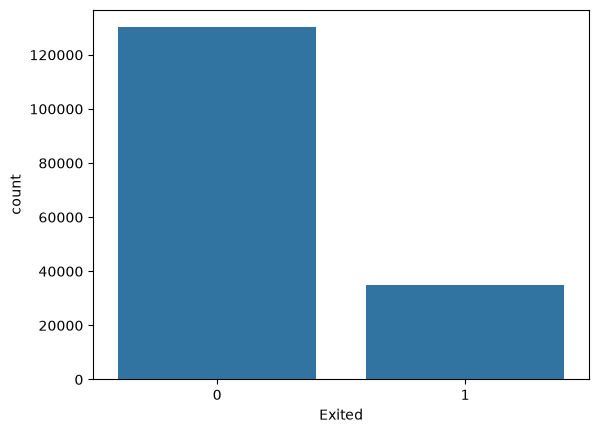

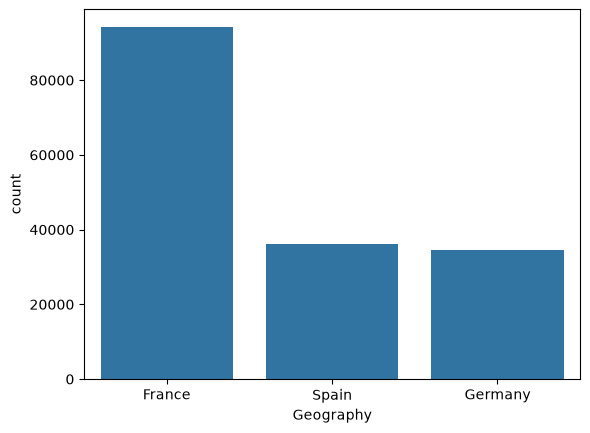

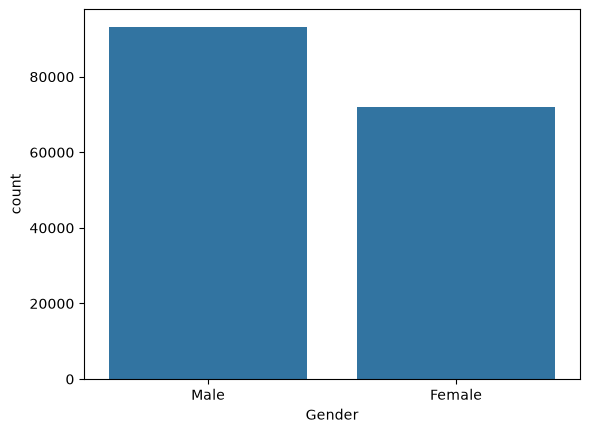

In [134]:
for col in cat_col:
    sns.countplot(df,x=df[col])
    plt.show()

In [135]:
#check the shape of data
print(f"The Number or Row in Train Dataset {df.shape[0]} & Columns is {df.shape[1]}")

The Number or Row in Train Dataset 165034 & Columns is 14


In [136]:
#splt the data in X & Y
X = df.drop(['Exited','Surname','id','CustomerId'],axis=1)
Y = df['Exited']

In [137]:
print(X.columns.tolist())

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']


In [138]:
print(cat_col)

['IsActiveMember', 'Tenure', 'NumOfProducts', 'HasCrCard', 'Exited', 'Geography', 'Gender']


In [139]:
from sklearn.preprocessing import LabelEncoder

cat_col = ['Geography', 'Gender']

for col in cat_col:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])

print(X[['Geography', 'Gender']].head(10))

   Geography  Gender
0          0       1
1          0       1
2          0       1
3          0       1
4          2       1
5          1       1
6          0       0
7          2       1
8          0       1
9          1       1


In [140]:
X.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,668,0,1,33.0,3,0.00,2,1.0,0.0,181449.97
1,627,0,1,33.0,1,0.00,2,1.0,1.0,49503.50
2,678,0,1,40.0,10,0.00,2,1.0,0.0,184866.69
3,581,0,1,34.0,2,148882.54,1,1.0,1.0,84560.88
4,716,2,1,33.0,5,0.00,2,1.0,1.0,15068.83


In [141]:
Y.value_counts()

Exited
0    130113
1     34921
Name: count, dtype: int64

In [142]:
# train test split the data
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [ ]:
# # create a deep neural network using tensorflow for binary classification
# import tensorflow as tf
# from tensorflow.keras.models import Sequential
# from tensorflow.keras.layers import Dense, Dropout

# model = Sequential(
#     [
#         Dense(units=16, input_dim=10, activation='relu'),
#         Dropout(0.2),
#         Dense(units=8, activation='relu'),
#         Dropout(0.2),
#         Dense(units=6, activation='relu'),
#         Dropout(0.2),
#         Dense(units=1, activation='sigmoid')
#     ]
# )

# ***Neural Network Architecture***

Epoch 1/50
4126/4126 ━━━━━━━━━━━━━━━━━━━━ 30s 6ms/step - accuracy: 0.6940 - loss: 8.4386 - val_accuracy: 0.7888 - val_loss: 0.5582
Epoch 2/50
4126/4126 ━━━━━━━━━━━━━━━━━━━━ 27s 7ms/step - accuracy: 0.7524 - loss: 1.1449 - val_accuracy: 0.7829 - val_loss: 0.5196
Epoch 3/50
4126/4126 ━━━━━━━━━━━━━━━━━━━━ 26s 6ms/step - accuracy: 0.7879 - loss: 0.5225 - val_accuracy: 0.7893 - val_loss: 0.5153
Epoch 4/50
4126/4126 ━━━━━━━━━━━━━━━━━━━━ 28s 7ms/step - accuracy: 0.7882 - loss: 0.5164 - val_accuracy: 0.7893 - val_loss: 0.5149
Epoch 5/50
4126/4126 ━━━━━━━━━━━━━━━━━━━━ 26s 6ms/step - accuracy: 0.7882 - loss: 0.5167 - val_accuracy: 0.7893 - val_loss: 0.5151
Epoch 6/50
4126/4126 ━━━━━━━━━━━━━━━━━━━━ 25s 6ms/step - accuracy: 0.7882 - loss: 0.5165 - val_accuracy: 0.7893 - val_loss: 0.5149
Epoch 7/50
4126/4126 ━━━━━━━━━━━━━━━━━━━━ 27s 7ms/step - accuracy: 0.7882 - loss: 0.5165 - val_accuracy: 0.7893 - val_loss: 0.5157
Epoch 8/50
4126/4126 ━━━━━━━━━━━━━━━━━━━━ 24s 6ms/step - accuracy: 0.7882 - loss: 0

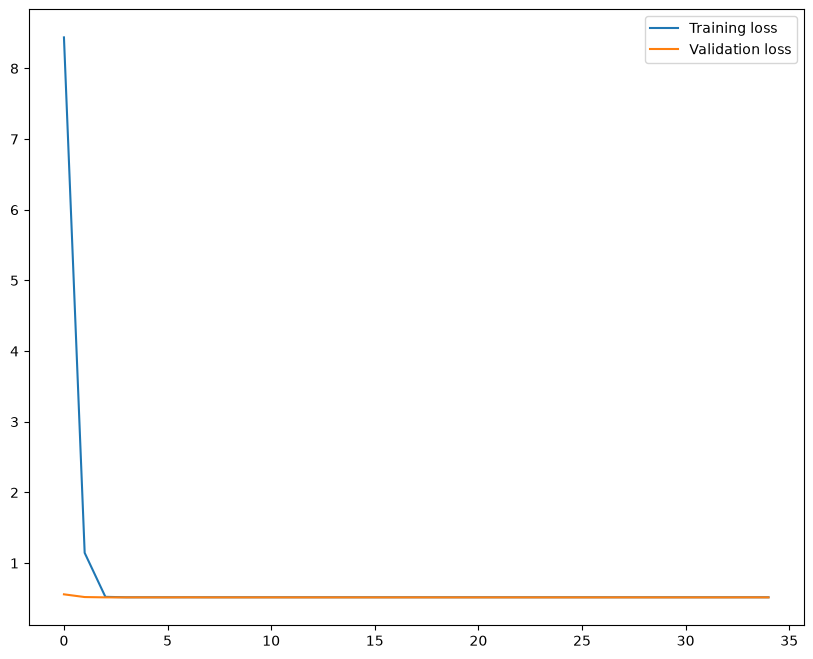

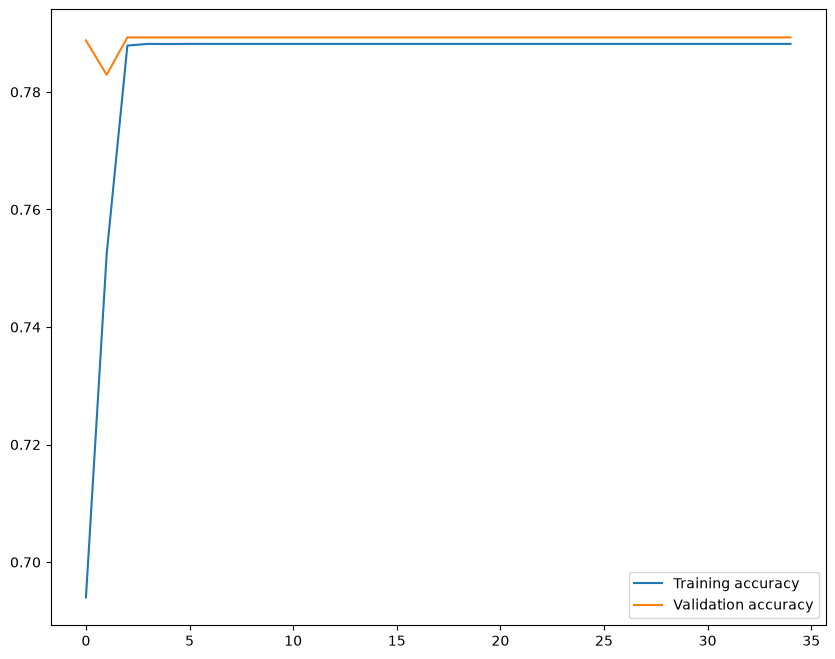

In [144]:
# create a deep neural network using tensorflow for binary classification
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping

# Building the model
model = tf.keras.models.Sequential([
    tf.keras.layers.Dense(128, activation='relu',
                          input_shape=(X_train.shape[1],)),  # Input layer
    tf.keras.layers.Dense(64, activation='relu'),  # Hidden layer 1
    tf.keras.layers.Dense(32, activation='relu'),  # Hidden layer 2
    tf.keras.layers.Dense(16, activation='relu'),  # Hidden layer 3
    tf.keras.layers.Dense(8, activation='relu'),   # Hidden layer 4

    tf.keras.layers.Dense(1, activation='sigmoid')  # Output layer
])

# Define the callback function
early_stopping = EarlyStopping(patience=15)

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# train the model and plot the training and testing loss and accuracy at each epoch
history = model.fit(X_train, y_train, epochs=50, batch_size=32, verbose=1, validation_data=(X_test, y_test),
                    callbacks=[early_stopping])


import matplotlib.pyplot as plt

# plot the training and testing loss and accuracy at each epoc
fig, ax = plt.subplots(figsize=(10, 8))
ax.plot(history.history['loss'], label='Training loss')
ax.plot(history.history['val_loss'], label='Validation loss')
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
ax.plot(history.history['accuracy'], label='Training accuracy')
ax.plot(history.history['val_accuracy'], label='Validation accuracy')
ax.legend()
plt.show()                   

Accuracy score:  0.866149604629321
Precision score:  0.866149604629321
Recall score:  0.866149604629321
F1 score:  0.866149604629321


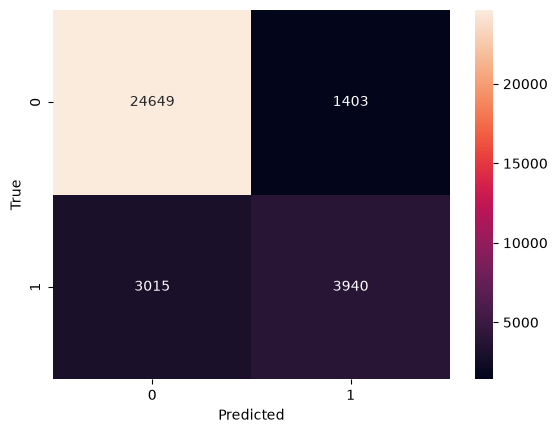

In [143]:
import matplotlib.pyplot as plt


from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# train the xgboost model
xgb = XGBClassifier()
xgb.fit(X_train, y_train)

# predict the test data
y_pred = xgb.predict(X_test)

print('Accuracy score: ', accuracy_score(y_test, y_pred))
print('Precision score: ', precision_score(y_test, y_pred, average='micro'))
print('Recall score: ', recall_score(y_test, y_pred, average='micro'))
print('F1 score: ', f1_score(y_test, y_pred, average='micro'))

# plot the confusion matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()